In [18]:
# Install required packages
import sys

!{sys.executable} -m pip install spacy pandas matplotlib seaborn

# Download English language model
!{sys.executable} -m spacy download en_core_web_sm

# Import libraries
import spacy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 21.7 MB/s  0:00:00m0:00:0100:01

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [19]:
# Import required libraries
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Load the English language model
try:
    nlp = spacy.load("en_core_web_sm")
    print("SpaCy model loaded successfully!")

except OSError:
    print("Error: English language model not found.")
    print("Please download en_core_web_sm first.")

SpaCy model loaded successfully!


### Task 1: Basic NER Implementation

In [20]:
import spacy

# Load the English language model
nlp = spacy.load("en_core_web_sm")

# Sample text for analysis
text = """
Apple Inc. is an American multinational technology company headquartered in Cupertino, California.
Steve Jobs was a co-founder of Apple Inc. and played a key role in the development of the Macintosh computer.
The Eiffel Tower is a wrought-iron lattice tower located on the Champ de Mars in Paris, France.
"""

# Process the text
doc = nlp(text)

# Print entities with their labels
print("Named Entities Found:")

for ent in doc.ents:
    print(f"Text: {ent.text:<30} Label: {ent.label_:<10} Description: {spacy.explain(ent.label_)}")

Named Entities Found:
Text: Apple Inc.                     Label: ORG        Description: Companies, agencies, institutions, etc.
Text: American                       Label: NORP       Description: Nationalities or religious or political groups
Text: Cupertino                      Label: GPE        Description: Countries, cities, states
Text: California                     Label: GPE        Description: Countries, cities, states
Text: Steve Jobs                     Label: PERSON     Description: People, including fictional
Text: Apple Inc.                     Label: ORG        Description: Companies, agencies, institutions, etc.
Text: Macintosh                      Label: ORG        Description: Companies, agencies, institutions, etc.
Text: The Eiffel Tower               Label: LOC        Description: Non-GPE locations, mountain ranges, bodies of water
Text: the Champ de Mars              Label: FAC        Description: Buildings, airports, highways, bridges, etc.
Text: Paris           

## Task 2: Entity Counting and Basic Visualization

In [21]:
def analyze_entities(text):
    doc = nlp(text)

    # Create a DataFrame of entities
    entities = [(ent.text, ent.label_, spacy.explain(ent.label_))
                for ent in doc.ents]

    df = pd.DataFrame(entities, columns=['Entity', 'Label', 'Description'])

    # Get entity counts
    label_counts = df['Label'].value_counts()

    return df, label_counts


# Analyze text
df_entities, entity_counts = analyze_entities(text)

print("\nEntity Analysis Summary:")
print(df_entities)

print("\nEntity Type Counts:")
print(entity_counts)


Entity Analysis Summary:
               Entity   Label  \
0          Apple Inc.     ORG   
1            American    NORP   
2           Cupertino     GPE   
3          California     GPE   
4          Steve Jobs  PERSON   
5          Apple Inc.     ORG   
6           Macintosh     ORG   
7    The Eiffel Tower     LOC   
8   the Champ de Mars     FAC   
9               Paris     GPE   
10             France     GPE   

                                          Description  
0             Companies, agencies, institutions, etc.  
1      Nationalities or religious or political groups  
2                           Countries, cities, states  
3                           Countries, cities, states  
4                         People, including fictional  
5             Companies, agencies, institutions, etc.  
6             Companies, agencies, institutions, etc.  
7   Non-GPE locations, mountain ranges, bodies of ...  
8        Buildings, airports, highways, bridges, etc.  
9                

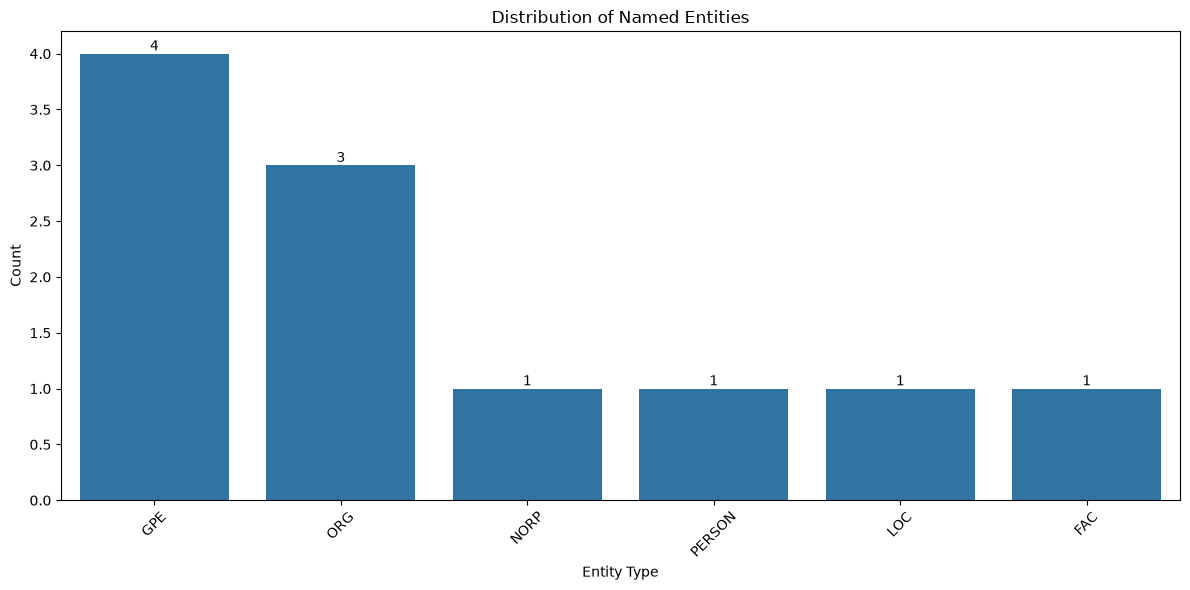

In [22]:
def plot_entity_distribution(entity_counts):
    plt.figure(figsize=(12, 6))

    sns.barplot(x=entity_counts.index, y=entity_counts.values)

    plt.title('Distribution of Named Entities')
    plt.xlabel('Entity Type')
    plt.ylabel('Count')

    # Add value labels on top of bars
    for i, v in enumerate(entity_counts.values):
        plt.text(i, v, str(v), ha='center', va='bottom')

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


plot_entity_distribution(entity_counts)


## Task 3: Enhanced Entity Frequency Analysis

In [23]:
def analyze_entity_frequencies(doc):
    entity_frequencies = {}

    # Count each entity
    for ent in doc.ents:
        key = (ent.text, ent.label_)

        if key in entity_frequencies:
            entity_frequencies[key] += 1
        else:
            entity_frequencies[key] = 1

    sorted_entities = sorted(
        entity_frequencies.items(),
        key=lambda item: item[1],
        reverse=True
    )

    return sorted_entities


# Analyze entity frequencies
entity_frequencies = analyze_entity_frequencies(doc)

print("Entity Frequency Analysis:")

for entity, count in entity_frequencies:
    print(f"Entity: {entity[0]:<20} Label: {entity[1]:<10} Count: {count}")


Entity Frequency Analysis:
Entity: Apple Inc.           Label: ORG        Count: 2
Entity: American             Label: NORP       Count: 1
Entity: Cupertino            Label: GPE        Count: 1
Entity: California           Label: GPE        Count: 1
Entity: Steve Jobs           Label: PERSON     Count: 1
Entity: Macintosh            Label: ORG        Count: 1
Entity: The Eiffel Tower     Label: LOC        Count: 1
Entity: the Champ de Mars    Label: FAC        Count: 1
Entity: Paris                Label: GPE        Count: 1
Entity: France               Label: GPE        Count: 1


## Task 4: Multi-word Entity Analysis

In [24]:
# Identify multi-word entities
multi_word_entities = []

for ent in doc.ents:
    if len(ent.text.split()) > 1:
        multi_word_entities.append(ent)

# Display multi-word entities
print("Multi-word Entities:")

for ent in multi_word_entities:
    print(f"Entity: {ent.text:<25} Label: {ent.label_}")
    
print("\nTotal Multi-word Entities:", len(multi_word_entities))

Multi-word Entities:
Entity: Apple Inc.                Label: ORG
Entity: Steve Jobs                Label: PERSON
Entity: Apple Inc.                Label: ORG
Entity: The Eiffel Tower          Label: LOC
Entity: the Champ de Mars         Label: FAC

Total Multi-word Entities: 5


In [25]:
# Count entity types before filtering
before_counts = df_entities['Label'].value_counts()

# Create a DataFrame for multi-word entities
multi_word_data = [
    (ent.text, ent.label_, spacy.explain(ent.label_))
    for ent in multi_word_entities
]

multi_word_df = pd.DataFrame(
    multi_word_data,
    columns=['Entity', 'Label', 'Description']
)

# Count entity types after filtering
after_counts = multi_word_df['Label'].value_counts()

after_counts = after_counts.reindex(
    before_counts.index, fill_value=0
)

print("Entity Counts Before Filtering:")
print(before_counts)

print("\nEntity Counts After Filtering:")
print(after_counts)


Entity Counts Before Filtering:
Label
GPE       4
ORG       3
NORP      1
PERSON    1
LOC       1
FAC       1
Name: count, dtype: int64

Entity Counts After Filtering:
Label
GPE       0
ORG       2
NORP      0
PERSON    1
LOC       1
FAC       1
Name: count, dtype: int64


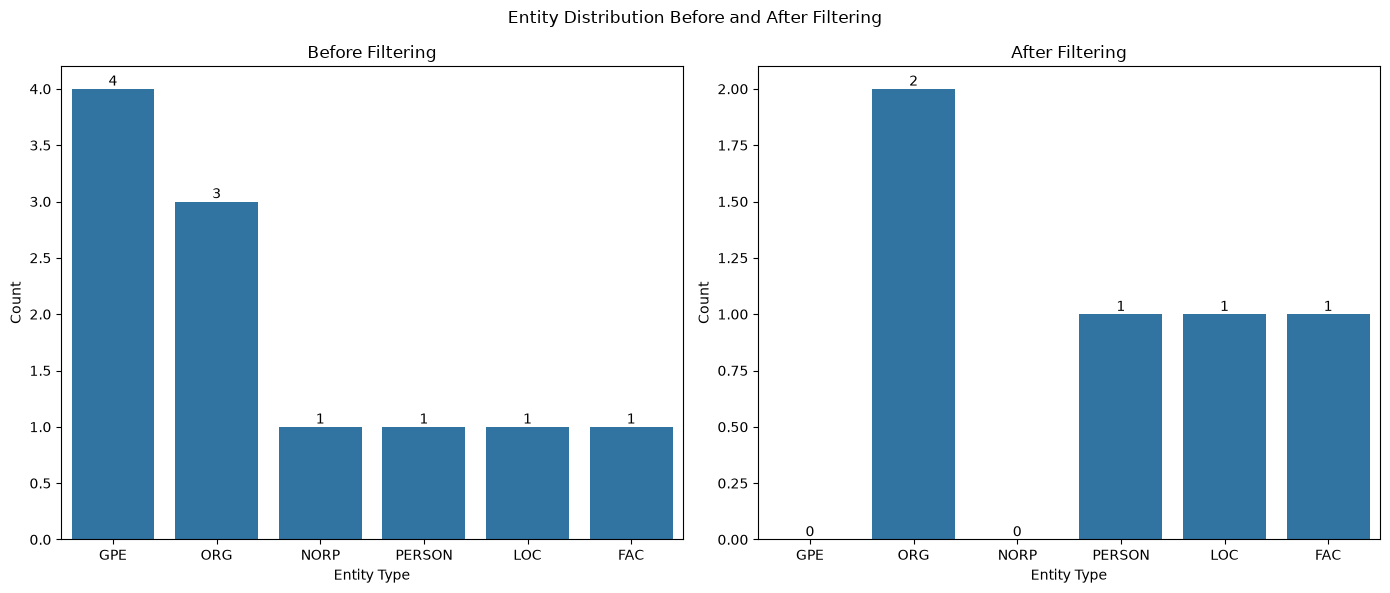

In [ ]:
def plot_entity_comparison(before_counts, after_counts):

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Plot distribution before filtering
    sns.barplot(
        x=before_counts.index,
        y=before_counts.values,
        ax=axes[0]
    )

    axes[0].set_title('Before Filtering')
    axes[0].set_xlabel('Entity Type')
    axes[0].set_ylabel('Count')

    for i, v in enumerate(before_counts.values):
        axes[0].text(i, v, str(v), ha='center', va='bottom')

    # Plot distribution after filtering
    sns.barplot(
        x=after_counts.index,
        y=after_counts.values,
        ax=axes[1]
    )

    axes[1].set_title('After Filtering')
    axes[1].set_xlabel('Entity Type')
    axes[1].set_ylabel('Count')

    # Add value labels
    for i, v in enumerate(after_counts.values):
        axes[1].text(i, v, str(v), ha='center', va='bottom')

    plt.suptitle('Entity Distribution Before and After Filtering')
    plt.tight_layout()
    plt.show()


plot_entity_comparison(before_counts, after_counts)


## Task 5: Summary Statistics

In [27]:
total_entities = len(doc.ents)

total_multi_word = len(multi_word_entities)

total_single_word = total_entities - total_multi_word

# Display summary statistics
print("Summary Statistics:")
print("------------------------------")

print("Total Entities:", total_entities)

print("Multi-word Entities:", total_multi_word)

print("Single-word Entities:", total_single_word)

print("\nEntity Distribution Before Filtering:")
print(before_counts)

print("\nEntity Distribution After Filtering:")
print(after_counts)

Summary Statistics:
------------------------------
Total Entities: 11
Multi-word Entities: 5
Single-word Entities: 6

Entity Distribution Before Filtering:
Label
GPE       4
ORG       3
NORP      1
PERSON    1
LOC       1
FAC       1
Name: count, dtype: int64

Entity Distribution After Filtering:
Label
GPE       0
ORG       2
NORP      0
PERSON    1
LOC       1
FAC       1
Name: count, dtype: int64


In [28]:
# Create a comparison DataFrame

comparison_df = pd.DataFrame({
    'Before Filtering': before_counts,
    'After Filtering': after_counts
})

comparison_df = comparison_df.fillna(0).astype(int)

print("Entity Distribution Comparison:")
print(comparison_df)

print("\nTotal Before Filtering:", before_counts.sum())
print("Total After Filtering:", after_counts.sum())

Entity Distribution Comparison:
        Before Filtering  After Filtering
Label                                    
GPE                    4                0
ORG                    3                2
NORP                   1                0
PERSON                 1                1
LOC                    1                1
FAC                    1                1

Total Before Filtering: 11
Total After Filtering: 5


### 1.	What is Named Entity Recognition (NER) and why is it useful in text analysis? Provide examples of practical applications.

NER is like reading a text and using a highlighter to mark names of people, companies, and locations. This process facilitates categorization and enables computers to grasp the content of a text more efficiently. For example, "Steve Jobs" is identified as a PERSON, "Apple Inc." as an ORG, and "Paris" as a GPE.

### 2.	Explain how you implemented the entity counting system. What data structures did you use and why?

I use spaCy to identify entities within a text. Then, I employ a dictionary acting like a ledger to record each entity's name and its frequency of occurrence. I also use tuples to store pairs of information: the entity's name and its type (for example, "Apple Inc." and "ORG" are stored together). Whenever "Apple Inc." appears again, the program increments its count by 1. Finally, I sort the results in descending order based on their frequency.

### 3.	Analyze your visualization approach: How does your bar graph represent the data? What insights can be gained from the visualization? How could the visualization be improved?

In this PE05, I use a bar chart to display the frequency of each entity type. Each bar represents a specific entity type, and its height indicates the number of occurrences. Looking at the chart, we can see that "GPE" appears most frequently 4 times, followed by "ORG" 3 times. The remaining types each appear only once. The chart could be improved by using different colors, adding labels, or displaying percentages to make comparisons easier for the reader. A taller bar indicates a higher frequency of that entity type.

### 4.	Discuss your implementation of multi-word entity filtering: What criteria did you use? How did it affect the results? What are the implications for NER accuracy?

I use "split()" to break down entity names into individual words. If an entity consists of more than one word, I keep it. If it consists of only a single word, I discard it. Starting with 11 entities, I am left with 5 after this filtering process. While this approach helps focus on multi-word names, it does not necessarily improve the accuracy of Named Entity Recognition (NER), as it also removes single-word names that may still be significant.

### 5.	Evaluate the performance of the NER system: What types of entities were successfully identified? Were there any misclassifications? How could the system be improved?

In this PE05, spaCy has identified various types of entities, such as PERSON, ORG, GPE, NORP, LOC, and FAC. However, the system may occasionally produce inaccurate classifications, as a single word can carry multiple meanings. For instance, "Macintosh" is classified as an ORG in our results, even though, in this context, it refers to a line of computers. This can be improved by incorporating additional context and verifying the results.